# Consumer Behavior Models: Evaluation Report

This is the executive summary for the downstream modeling stage. It pulls together every
model trained against the consumer telemetry feature store and states what each one can and
cannot do.

**Contents**

1. Data overview
2. Purchase propensity model
3. App switching model
4. Customer lifetime value
5. User segmentation
6. Business recommendations

**Two things to keep in mind when reading the numbers.**

The data is simulated. Each synthetic shopper carries latent traits (activity level, purchase
propensity, price sensitivity, app loyalty, spend tier, and an optional dormancy onset) that
drive both their observed history and their future behavior, which is what makes the forward
targets learnable at all. Absolute metrics are therefore a property of the generator as much as
of the models, and would differ on production telemetry.

Every evaluation figure is computed on a test split whose feature reference date *and* target
window both fall strictly later than the training split's. Features come only from events at or
before the reference date; targets come only from events after it.

In [1]:
# Notebook bootstrap: make the project importable and anchor relative paths.
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)

Project root: /home/nikhil/tindal-data-pipeline/consumer-telemetry


In [2]:
import json

import duckdb
import numpy as np
import polars as pl
from IPython.display import Image, display

from src.config import (
    ARTIFACTS_DIR,
    DEFAULT_DB_PATH,
    PRIMARY_TARGET,
    SWITCHING_TARGET,
    USER_CLV_PATH,
    USER_SEGMENTS_PATH,
)

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)


def load_summary(name):
    """Reads one of the JSON summaries written by the model modules."""
    path = ARTIFACTS_DIR / name
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def show(name):
    """Displays a generated figure from the artifacts directory."""
    display(Image(filename=str(ARTIFACTS_DIR / name)))


propensity = load_summary("propensity_metrics.json")
evaluation = load_summary("propensity_evaluation_summary.json")
switching = load_summary("switching_metrics.json")
clv = load_summary("clv_summary.json")
segmentation = load_summary("segmentation_summary.json")
print("Loaded all five model summaries.")

Loaded all five model summaries.


## 1. Data Overview

The warehouse is a star schema in DuckDB: a `fact_events` table of individual interactions,
joined to `dim_users` and `dim_products`, with a `fact_cross_app_comparisons` table recording
instances of the same product viewed across multiple apps inside the comparison window.

In [3]:
con = duckdb.connect(str(DEFAULT_DB_PATH), read_only=True)

overview = con.execute("""
    SELECT
        COUNT(*)                          AS events,
        COUNT(DISTINCT user_id)           AS users,
        COUNT(DISTINCT canonical_product_id) AS products,
        COUNT(DISTINCT session_id)        AS sessions,
        MIN(timestamp)                    AS first_event,
        MAX(timestamp)                    AS last_event
    FROM fact_events
""").pl()
print(overview)

print()
print(con.execute("""
    SELECT action, COUNT(*) AS events,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM fact_events GROUP BY action ORDER BY events DESC
""").pl())

print()
print(con.execute("""
    SELECT currency, COUNT(*) AS events, ROUND(AVG(price), 2) AS avg_listed_price
    FROM fact_events GROUP BY currency ORDER BY events DESC
""").pl())

shape: (1, 6)
┌────────┬───────┬──────────┬──────────┬─────────────────────┬─────────────────────┐
│ events ┆ users ┆ products ┆ sessions ┆ first_event         ┆ last_event          │
│ ---    ┆ ---   ┆ ---      ┆ ---      ┆ ---                 ┆ ---                 │
│ i64    ┆ i64   ┆ i64      ┆ i64      ┆ datetime[μs]        ┆ datetime[μs]        │
╞════════╪═══════╪══════════╪══════════╪═════════════════════╪═════════════════════╡
│ 173277 ┆ 1000  ┆ 847      ┆ 53273    ┆ 2026-09-28 09:10:32 ┆ 2026-11-26 23:40:58 │
└────────┴───────┴──────────┴──────────┴─────────────────────┴─────────────────────┘

shape: (3, 3)
┌────────┬────────┬───────┐
│ action ┆ events ┆ pct   │
│ ---    ┆ ---    ┆ ---   │
│ str    ┆ i64    ┆ f64   │
╞════════╪════════╪═══════╡
│ view   ┆ 146751 ┆ 84.69 │
│ cart   ┆ 13889  ┆ 8.02  │
│ buy    ┆ 12637  ┆ 7.29  │
└────────┴────────┴───────┘

shape: (2, 3)
┌──────────┬────────┬──────────────────┐
│ currency ┆ events ┆ avg_listed_price │
│ ---      ┆ ---    ┆ ---  

In [4]:
train = pl.read_parquet("data/features/train_features.parquet")
test = pl.read_parquet("data/features/test_features.parquet")

# Train stacks one block per train reference date, so its rows are (user, reference_date)
# pairs; rates below are pooled over those rows. Test has one row per user.
print(f"Train matrix: {train.shape[0]} rows ({train['user_id'].n_unique()} users x "
      f"{train['reference_date'].n_unique()} reference dates) x {train.shape[1]} columns")
print(f"Test matrix : {test.shape[0]} rows ({test['user_id'].n_unique()} users) x {test.shape[1]} columns")
print()
print(pl.DataFrame([
    {
        "split": name,
        "rows": df.height,
        "will_purchase_next_7d": int(df[PRIMARY_TARGET].sum()),
        "purchase_rate": round(float(df[PRIMARY_TARGET].mean()), 4),
        "will_switch_app_next_7d": int(df[SWITCHING_TARGET].sum()),
        "switch_rate": round(float(df[SWITCHING_TARGET].mean()), 4),
    }
    for name, df in (("train", train), ("test", test))
]))

selected = json.load(open("data/features/selected_features.json"))
print()
print(f"Candidate features: {selected['total_candidate_features']}, "
      f"selected after collinearity pruning: {selected['selected_feature_count']}")
con.close()

Train matrix: 5000 rows (1000 users x 5 reference dates) x 39 columns
Test matrix : 1000 rows (1000 users) x 39 columns

shape: (2, 6)
┌───────┬──────┬───────────────────────┬───────────────┬─────────────────────────┬─────────────┐
│ split ┆ rows ┆ will_purchase_next_7d ┆ purchase_rate ┆ will_switch_app_next_7d ┆ switch_rate │
│ ---   ┆ ---  ┆ ---                   ┆ ---           ┆ ---                     ┆ ---         │
│ str   ┆ i64  ┆ i64                   ┆ f64           ┆ i64                     ┆ f64         │
╞═══════╪══════╪═══════════════════════╪═══════════════╪═════════════════════════╪═════════════╡
│ train ┆ 5000 ┆ 2886                  ┆ 0.5772        ┆ 1913                    ┆ 0.3826      │
│ test  ┆ 1000 ┆ 508                   ┆ 0.508         ┆ 329                     ┆ 0.329       │
└───────┴──────┴───────────────────────┴───────────────┴─────────────────────────┴─────────────┘

Candidate features: 33, selected after collinearity pruning: 33


## 2. Purchase Propensity Model

A LightGBM binary classifier predicting `will_purchase_next_7d`.

Early stopping follows binary log loss rather than AUC. That choice matters: stopping on AUC
halted the fit after four boosting rounds on a metric plateau and squeezed every predicted
probability into a narrow band around the base rate, which would have left the calibration and
lift analysis below meaningless.

In [5]:
rows = []
for split in ("train", "test"):
    m = propensity[split]
    rows.append({
        "split": split,
        "n": m["n_samples"],
        "positive_rate": round(m["positive_rate"], 4),
        "roc_auc": round(m["roc_auc"], 4),
        "pr_auc": round(m["pr_auc"], 4),
        "f1": round(m["f1"], 4),
        "log_loss": round(m["log_loss"], 4),
        "brier": round(m["brier_score"], 4),
    })
print(pl.DataFrame(rows))

cm = propensity["test"]["confusion_matrix"]
print()
print("Test confusion matrix at threshold 0.50:")
print(f"  true negative  {cm['true_negative']:>4}   false positive {cm['false_positive']:>4}")
print(f"  false negative {cm['false_negative']:>4}   true positive  {cm['true_positive']:>4}")

gap = propensity["train"]["roc_auc"] - propensity["test"]["roc_auc"]
print()
print(f"Train minus test ROC-AUC: {gap:.4f}")
print("A small gap is what matters here: the matrix is only a few hundred rows wide, so an")
print("unconstrained model would memorize it outright.")

shape: (2, 8)
┌───────┬──────┬───────────────┬─────────┬────────┬────────┬──────────┬────────┐
│ split ┆ n    ┆ positive_rate ┆ roc_auc ┆ pr_auc ┆ f1     ┆ log_loss ┆ brier  │
│ ---   ┆ ---  ┆ ---           ┆ ---     ┆ ---    ┆ ---    ┆ ---      ┆ ---    │
│ str   ┆ i64  ┆ f64           ┆ f64     ┆ f64    ┆ f64    ┆ f64      ┆ f64    │
╞═══════╪══════╪═══════════════╪═════════╪════════╪════════╪══════════╪════════╡
│ train ┆ 5000 ┆ 0.5772        ┆ 0.8646  ┆ 0.8889 ┆ 0.8143 ┆ 0.4569   ┆ 0.1491 │
│ test  ┆ 1000 ┆ 0.508         ┆ 0.8858  ┆ 0.8773 ┆ 0.805  ┆ 0.4171   ┆ 0.1364 │
└───────┴──────┴───────────────┴─────────┴────────┴────────┴──────────┴────────┘

Test confusion matrix at threshold 0.50:
  true negative   381   false positive  111
  false negative   91   true positive   417

Train minus test ROC-AUC: -0.0213
A small gap is what matters here: the matrix is only a few hundred rows wide, so an
unconstrained model would memorize it outright.


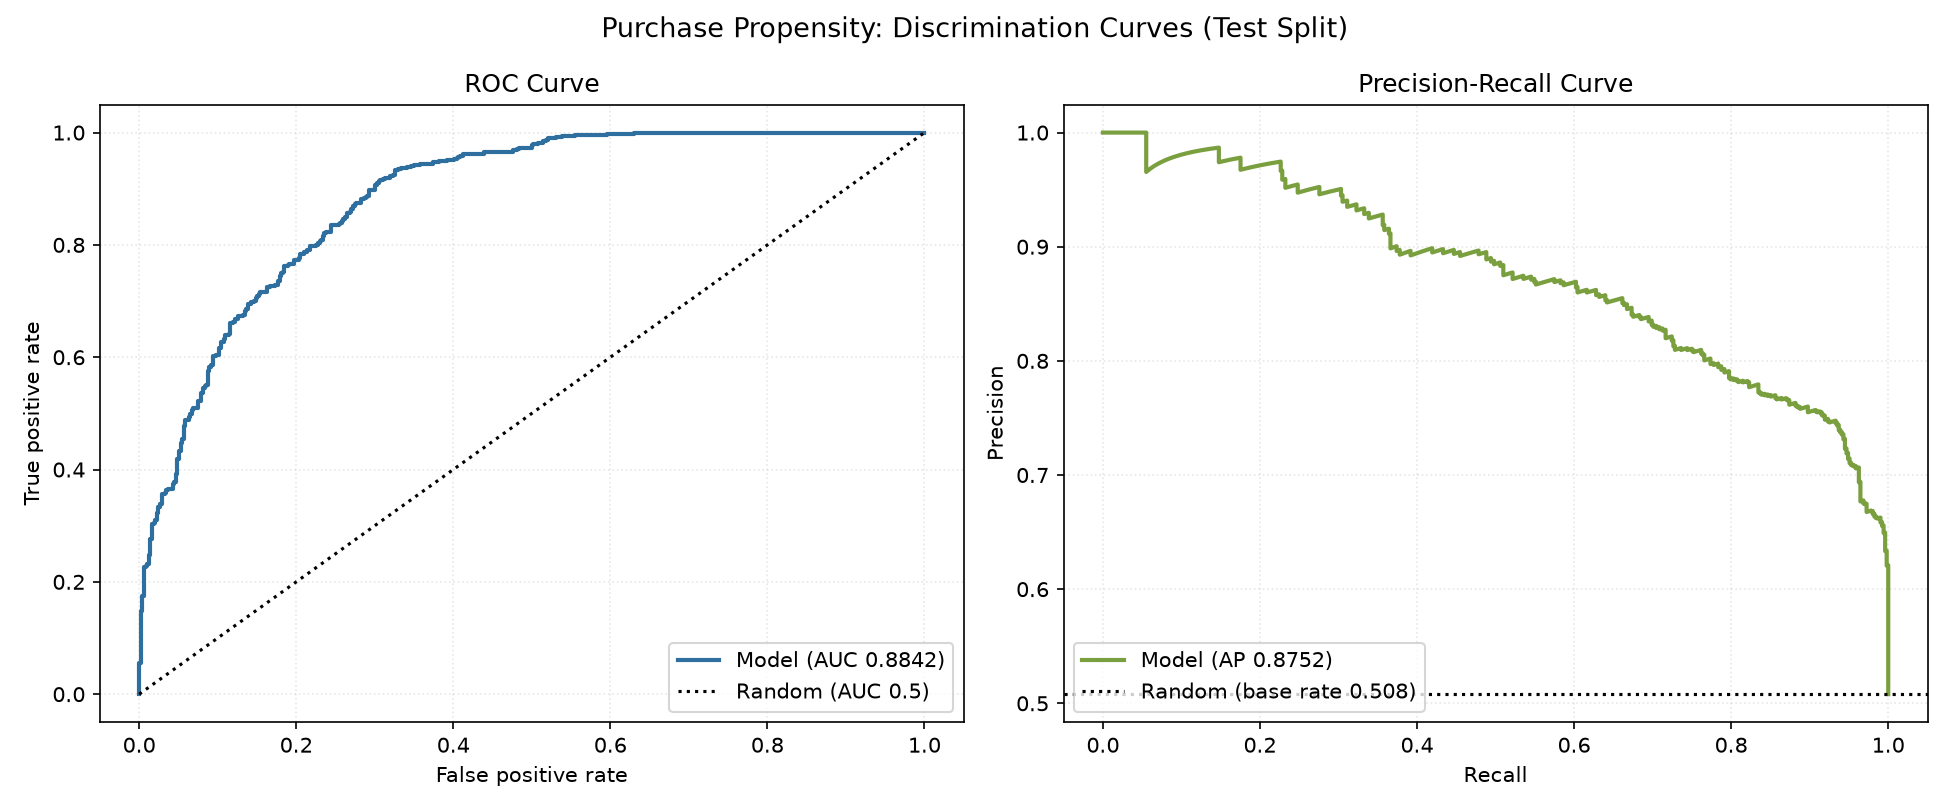

In [6]:
show("propensity_roc_pr_curves.png")

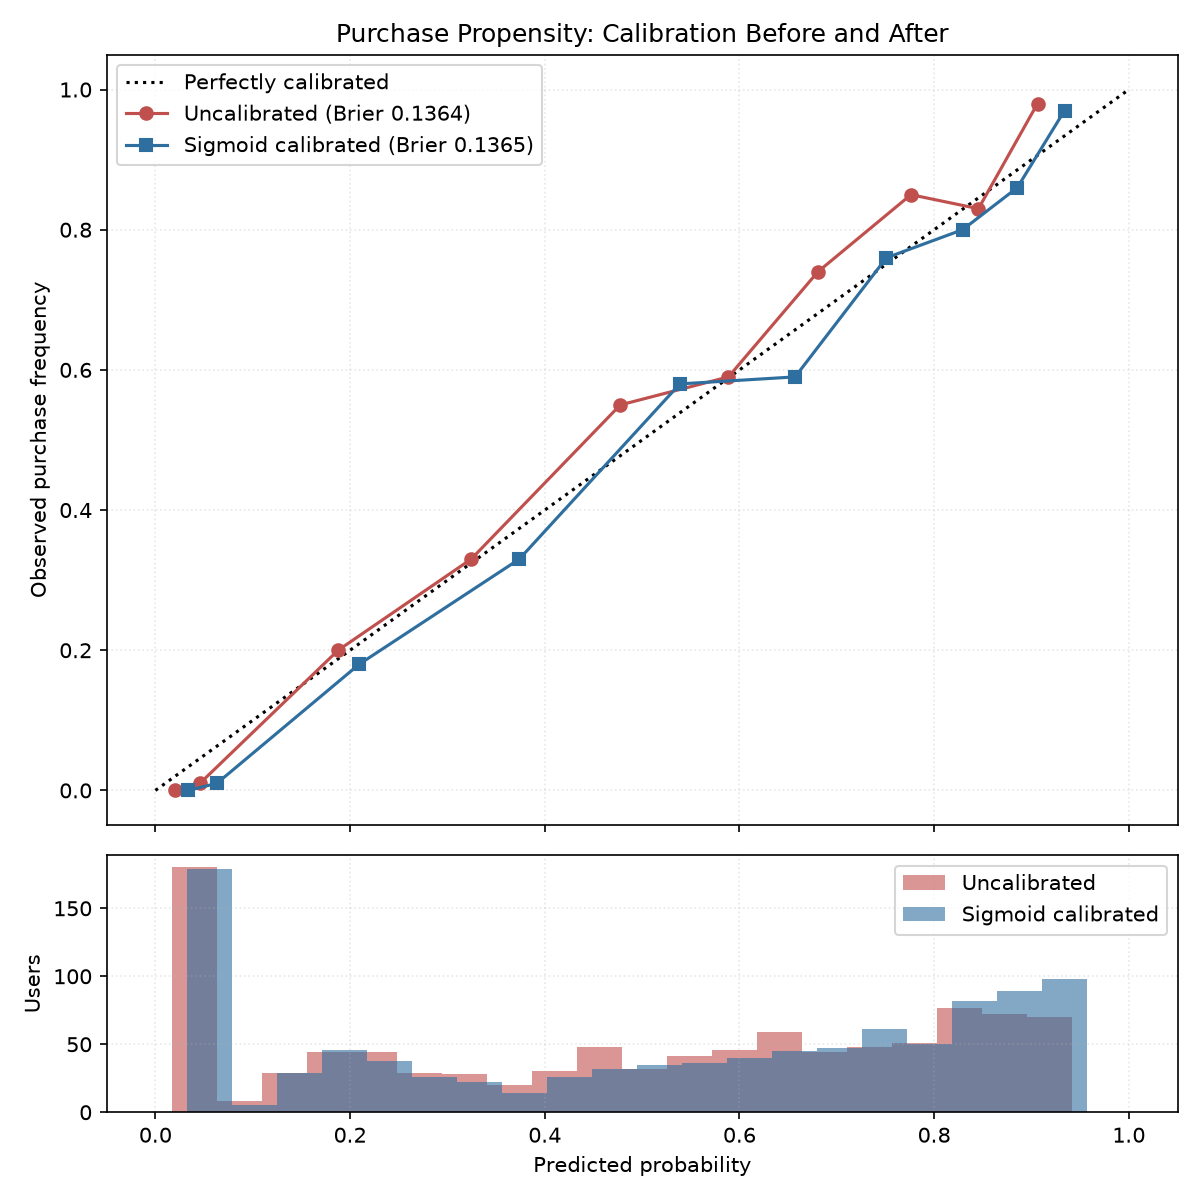

Calibration method evaluated: sigmoid
Recalibration improves on uncalibrated: True

shape: (3, 4)
┌──────────────┬─────────────┬──────────┬─────────┐
│ variant      ┆ brier_score ┆ log_loss ┆ roc_auc │
│ ---          ┆ ---         ┆ ---      ┆ ---     │
│ str          ┆ f64         ┆ f64      ┆ f64     │
╞══════════════╪═════════════╪══════════╪═════════╡
│ uncalibrated ┆ 0.1669      ┆ 0.5027   ┆ 0.8281  │
│ sigmoid      ┆ 0.1641      ┆ 0.4942   ┆ 0.8278  │
│ isotonic     ┆ 0.1644      ┆ 0.4973   ┆ 0.824   │
└──────────────┴─────────────┴──────────┴─────────┘

The model optimizes log loss, a proper scoring rule, so it starts close to calibrated
and there is no large miscalibration to repair.
Brier spread across all three variants: 0.0028, so the choice is a refinement
rather than a correction. Selected variant: sigmoid.
Either way the score can be read directly as an expected purchase rate.


In [7]:
show("propensity_calibration_curve.png")

print("Calibration method evaluated:", evaluation["calibration_method"])
print("Recalibration improves on uncalibrated:",
      evaluation["method_selection"]["improves_on_uncalibrated"])
print()
print(pl.DataFrame([
    {"variant": name, **{k: round(v, 4) for k, v in scores.items()}}
    for name, scores in evaluation["method_selection"]["cv_scores"].items()
]))
cv = evaluation["method_selection"]["cv_scores"]
best = evaluation["calibration_method"]
spread = max(s["brier_score"] for s in cv.values()) - min(s["brier_score"] for s in cv.values())

print()
print("The model optimizes log loss, a proper scoring rule, so it starts close to calibrated")
print("and there is no large miscalibration to repair.")
print(f"Brier spread across all three variants: {spread:.4f}, so the choice is a refinement")
print(f"rather than a correction. Selected variant: {best}.")
print("Either way the score can be read directly as an expected purchase rate.")

In [8]:
lift = pl.DataFrame(evaluation["decile_table"])
print(lift.select([
    "decile", "users", "mean_predicted_probability",
    "actual_purchasers", "actual_purchase_rate", "lift", "cumulative_capture_pct",
]))

base_rate = propensity["test"]["positive_rate"]
print()
print(f"Base rate {base_rate:.4f} caps the attainable lift at {1 / base_rate:.2f}.")
print(f"Observed top decile lift: {evaluation['top_decile_lift']:.2f}")

shape: (10, 7)
┌────────┬───────┬────────────────────────────┬───────────────────┬──────────────────────┬──────────┬────────────────────────┐
│ decile ┆ users ┆ mean_predicted_probability ┆ actual_purchasers ┆ actual_purchase_rate ┆ lift     ┆ cumulative_capture_pct │
│ ---    ┆ ---   ┆ ---                        ┆ ---               ┆ ---                  ┆ ---      ┆ ---                    │
│ i64    ┆ i64   ┆ f64                        ┆ i64               ┆ f64                  ┆ f64      ┆ f64                    │
╞════════╪═══════╪════════════════════════════╪═══════════════════╪══════════════════════╪══════════╪════════════════════════╡
│ 1      ┆ 100   ┆ 0.933938                   ┆ 97                ┆ 0.97                 ┆ 1.909449 ┆ 0.190945               │
│ 2      ┆ 100   ┆ 0.885401                   ┆ 86                ┆ 0.86                 ┆ 1.692913 ┆ 0.360236               │
│ 3      ┆ 100   ┆ 0.829226                   ┆ 80                ┆ 0.8                  ┆ 1.574

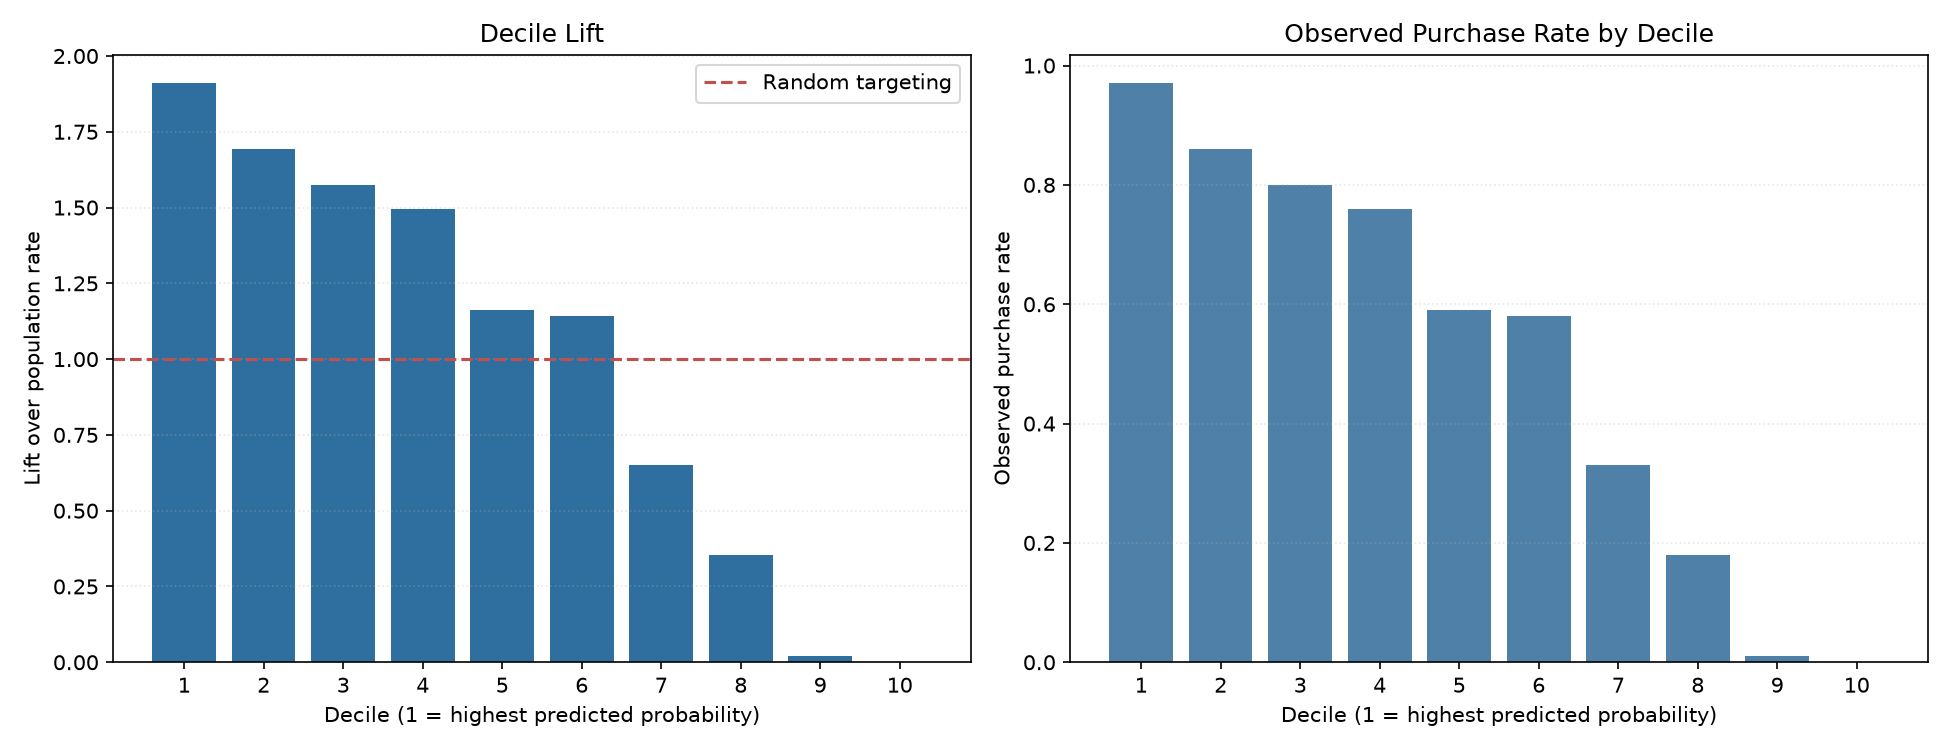

In [9]:
show("propensity_lift_chart.png")

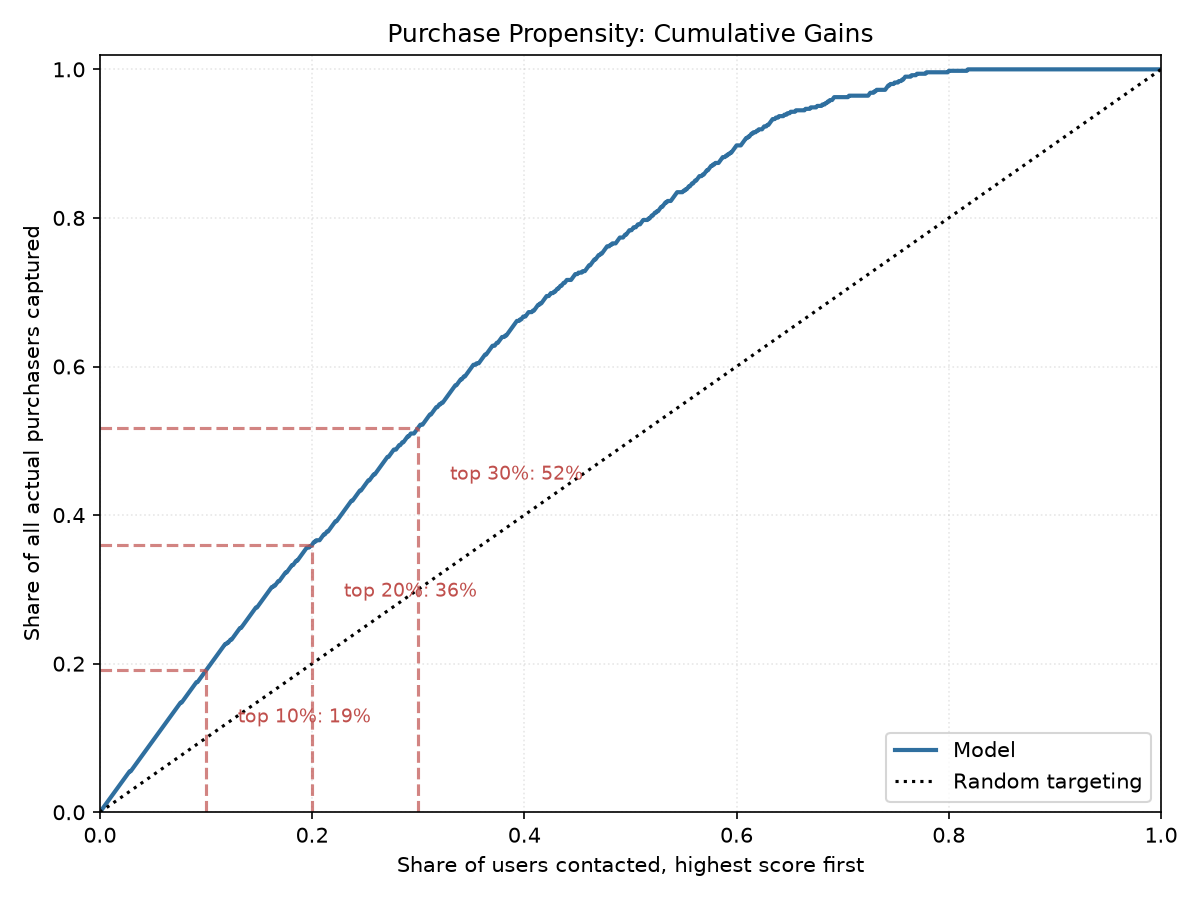

  Top 10 percent of scored users captures 19.1% of all purchasers
  Top 20 percent of scored users captures 36.0% of all purchasers
  Top 30 percent of scored users captures 51.8% of all purchasers


In [10]:
show("propensity_cumulative_gains.png")

for key, label in (("capture_top_10_pct", "10"), ("capture_top_20_pct", "20"),
                   ("capture_top_30_pct", "30")):
    print(f"  Top {label:>2} percent of scored users captures "
          f"{evaluation[key]:.1%} of all purchasers")

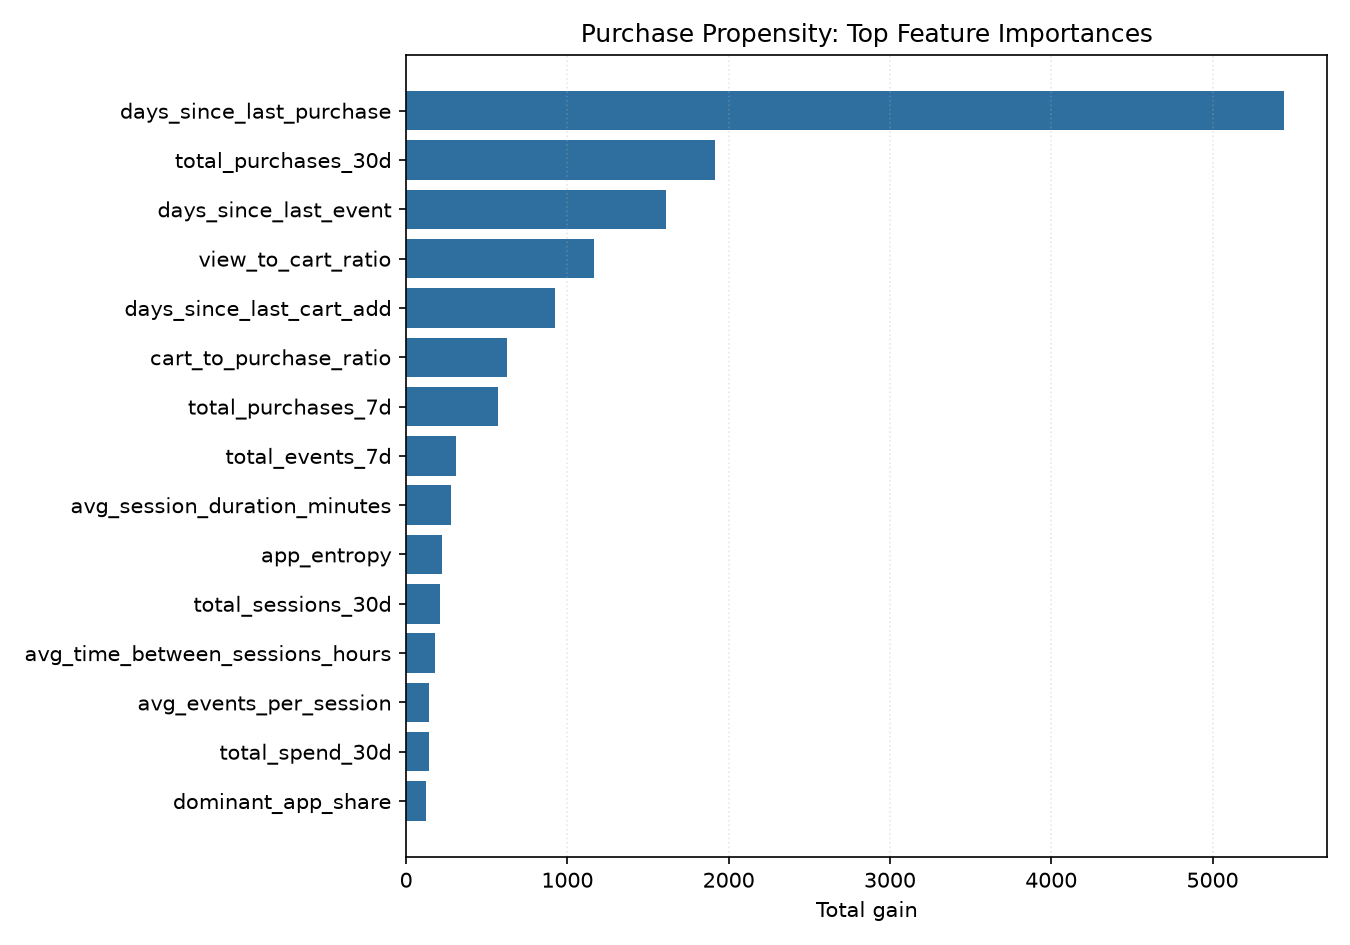

In [11]:
show("propensity_feature_importance.png")

## 3. App Switching Model

Two formulations of the same question. The binary model predicts whether a user's next purchase
lands on an app other than their historical dominant app. The three-class model separates the
three possible outcomes directly: no purchase, purchase on the dominant app, or purchase
elsewhere.

Switching is a minority outcome, so the binary decision threshold is tuned on the training
split and then applied unchanged to test. At the default 0.5 cutoff recall was being suppressed
badly.

In [12]:
b_test = switching["binary_test"]
b_tuned = switching["binary_test_tuned_threshold"]

print(pl.DataFrame([
    {"variant": f"test @ 0.50", "roc_auc": round(b_test["roc_auc"], 4),
     "pr_auc": round(b_test["pr_auc"], 4), "f1": round(b_test["f1"], 4),
     "accuracy": round(b_test["accuracy"], 4)},
    {"variant": f"test @ {switching['tuned_threshold']:.2f}", "roc_auc": round(b_tuned["roc_auc"], 4),
     "pr_auc": round(b_tuned["pr_auc"], 4), "f1": round(b_tuned["f1"], 4),
     "accuracy": round(b_tuned["accuracy"], 4)},
]))

print()
print(f"Threshold tuned on train: {switching['tuned_threshold']:.2f}")
print(f"F1 on test: {b_test['f1']:.4f} at 0.50, rising to {b_tuned['f1']:.4f} at the tuned cutoff.")
print("Ranking quality is identical either way, since ROC-AUC and PR-AUC do not depend on a")
print("threshold. Only the operating point changes.")

mc = switching["multiclass_test"]
print()
print(f"Three-class test accuracy {mc['accuracy']:.4f}, macro F1 {mc['macro_f1']:.4f}")
counts = {k: v for k, v in mc["class_distribution"].items()}
majority = max(counts.values()) / sum(counts.values())
print(f"Majority-class baseline would be {majority:.4f}, so the model adds real information.")
print(f"Test class distribution: {counts}")

shape: (2, 5)
┌─────────────┬─────────┬────────┬────────┬──────────┐
│ variant     ┆ roc_auc ┆ pr_auc ┆ f1     ┆ accuracy │
│ ---         ┆ ---     ┆ ---    ┆ ---    ┆ ---      │
│ str         ┆ f64     ┆ f64    ┆ f64    ┆ f64      │
╞═════════════╪═════════╪════════╪════════╪══════════╡
│ test @ 0.50 ┆ 0.8464  ┆ 0.7118 ┆ 0.6501 ┆ 0.775    │
│ test @ 0.38 ┆ 0.8464  ┆ 0.7118 ┆ 0.6795 ┆ 0.751    │
└─────────────┴─────────┴────────┴────────┴──────────┘

Threshold tuned on train: 0.38
F1 on test: 0.6501 at 0.50, rising to 0.6795 at the tuned cutoff.
Ranking quality is identical either way, since ROC-AUC and PR-AUC do not depend on a
threshold. Only the operating point changes.

Three-class test accuracy 0.6960, macro F1 0.6289
Majority-class baseline would be 0.4920, so the model adds real information.
Test class distribution: {'no_purchase': 492, 'bought_on_dominant_app': 179, 'switched_app': 329}


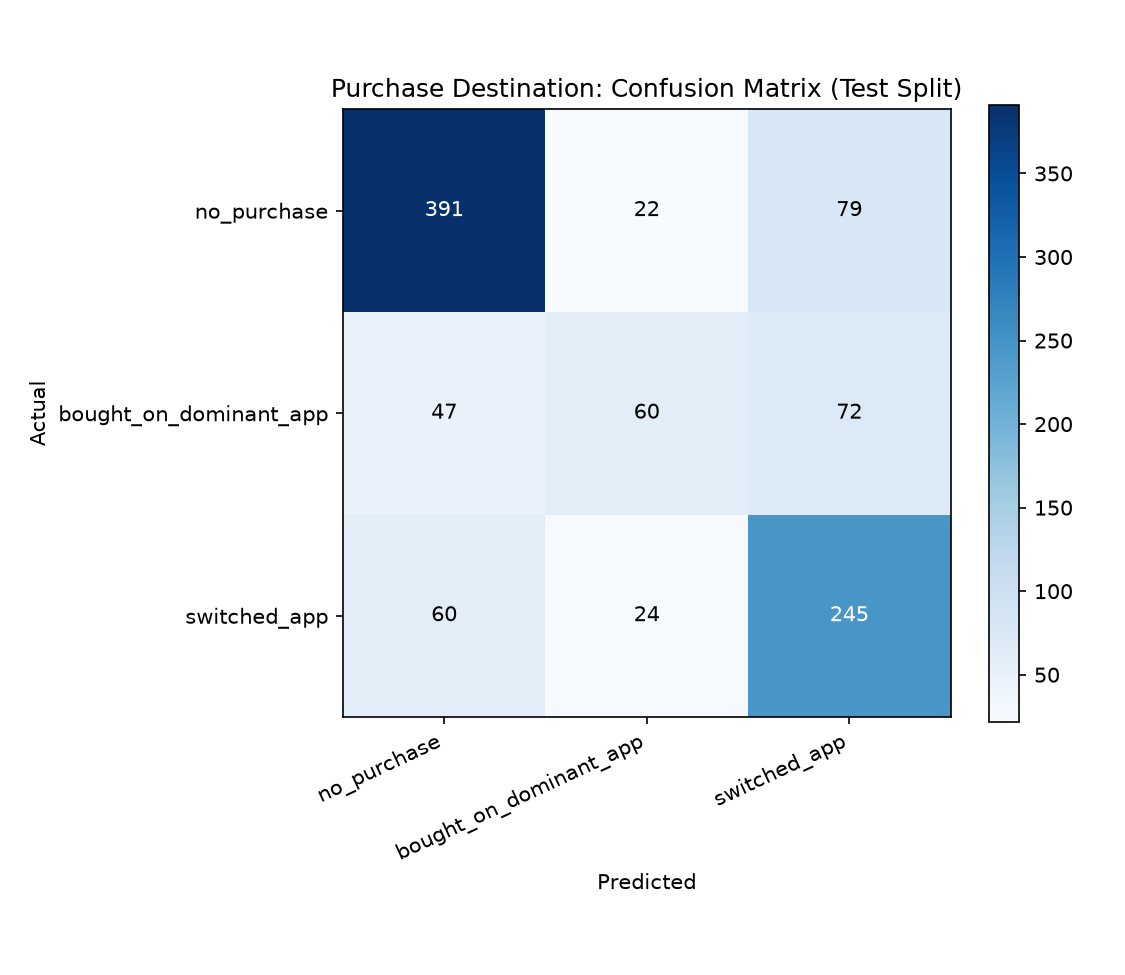

In [13]:
show("switching_confusion_matrix.png")

In [14]:
drivers = pl.DataFrame(switching["top_shap_drivers"])
print(drivers)
print()
print("Top three drivers of switching:")
for row in drivers.head(3).iter_rows(named=True):
    print(f"  {row['rank']}. {row['feature']} -- {row['effect']} "
          f"(mean |SHAP| {row['mean_abs_shap']:.4f})")
print()
print("The direction column is the correlation between a feature's value and its SHAP")
print("contribution, so it reads as the sign of the effect rather than just its size.")

shape: (5, 5)
┌──────┬──────────────────────────┬───────────────┬───────────┬─────────────────────┐
│ rank ┆ feature                  ┆ mean_abs_shap ┆ direction ┆ effect              │
│ ---  ┆ ---                      ┆ ---           ┆ ---       ┆ ---                 │
│ i64  ┆ str                      ┆ f64           ┆ f64       ┆ str                 │
╞══════╪══════════════════════════╪═══════════════╪═══════════╪═════════════════════╡
│ 1    ┆ days_since_last_event    ┆ 0.405259      ┆ -0.891674 ┆ reduces switching   │
│ 2    ┆ days_since_last_purchase ┆ 0.400744      ┆ -0.373903 ┆ reduces switching   │
│ 3    ┆ view_to_cart_ratio       ┆ 0.240772      ┆ 0.888762  ┆ increases switching │
│ 4    ┆ dominant_app_share       ┆ 0.176612      ┆ -0.950546 ┆ reduces switching   │
│ 5    ┆ total_purchases_30d      ┆ 0.138077      ┆ 0.873108  ┆ increases switching │
└──────┴──────────────────────────┴───────────────┴───────────┴─────────────────────┘

Top three drivers of switching:
  1. da

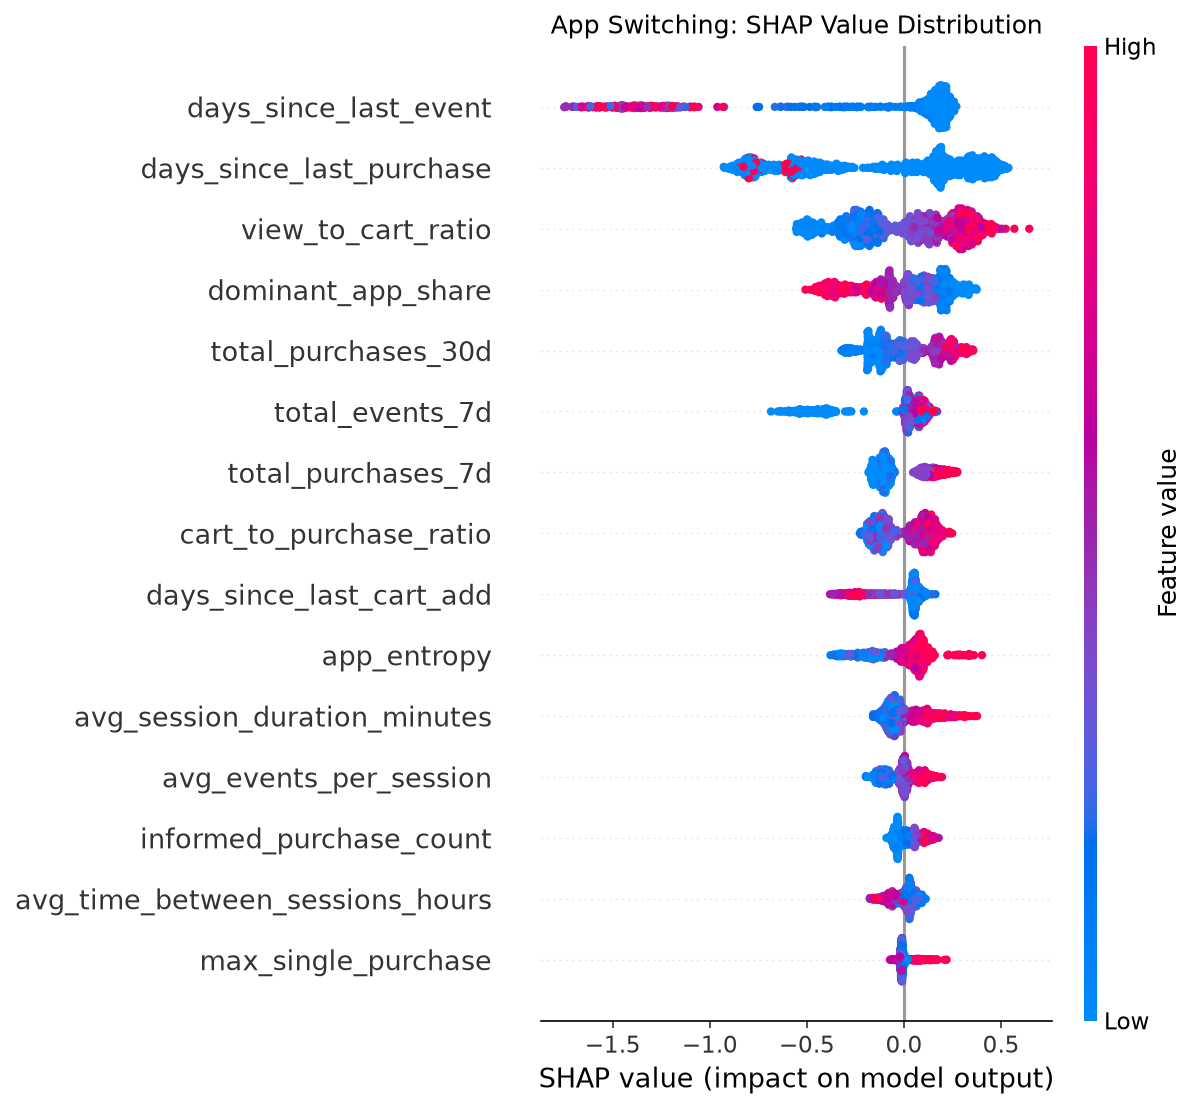

In [15]:
show("switching_shap_summary.png")

## 4. Customer Lifetime Value

BG/NBD models purchase frequency and dropout; Gamma-Gamma models average order value. CLV is
the product of expected purchases over the horizon and expected order value.

Revenue is normalized to INR before fitting, because the event stream mixes INR and USD
listings and an unnormalized monetary value would make dollar purchases look two orders of
magnitude cheaper than identical rupee ones.

In [16]:
print(f"Customers modeled      : {clv['n_customers']}")
print(f"With repeat purchases  : {clv['n_repeat_customers']}")
print(f"Transactions           : {clv['n_transactions']}")
print(f"Horizon                : {clv['horizon_days']} days")
print()
print("BG/NBD parameters:", {k: round(v, 4) for k, v in clv["bgnbd_params"].items()})
print("Gamma-Gamma parameters:", {k: round(v, 4) for k, v in clv["gamma_gamma_params"].items()})
print()
print(f"Mean predicted CLV   : {clv['mean_predicted_clv']:,.0f} INR")
print(f"Median predicted CLV : {clv['median_predicted_clv']:,.0f} INR")
print(f"Total book value     : {clv['total_predicted_clv']:,.0f} INR")

Customers modeled      : 920
With repeat purchases  : 843
Transactions           : 10582
Horizon                : 30 days

BG/NBD parameters: {'r': 1.9634, 'alpha': 9.2733, 'a': 0.0753, 'b': 1.8795}
Gamma-Gamma parameters: {'p': 9.8356, 'q': 0.1985, 'v': 9.7854}

Mean predicted CLV   : 142,466 INR
Median predicted CLV : 95,135 INR
Total book value     : 131,068,506 INR


In [17]:
print("Model fit diagnostics and caveats")
print()
print(f"  Frequency / monetary correlation: {clv['frequency_monetary_correlation']:.4f}")
print("  Gamma-Gamma assumes order value is independent of purchase frequency. A value near")
print("  zero supports that assumption.")
print()
print(f"  Gamma-Gamma q below 1: {clv['gamma_gamma_q_below_one']}")
if clv["gamma_gamma_q_below_one"]:
    print("  With q below 1 the population prior mean p*v/(q-1) is negative and cannot be used")
    print("  for one-off buyers, whose conditional expectation collapses to exactly that prior.")
    print(f"  Those {clv['order_value_fallback_count']} customers fall back to their own observed")
    print("  order value; the rest keep the fitted estimate. Every row records which it used.")
print()
print(f"  Purchase estimate fallbacks: {clv['purchase_fallback_count']}")
print("  BG/NBD dropout is only identifiable because a quarter of the simulated population")
print("  goes dormant partway through the window. Without that churn the parameter collapses")
print("  toward zero and P(alive) degenerates to 1.0 for every user.")

Model fit diagnostics and caveats

  Frequency / monetary correlation: 0.0718
  Gamma-Gamma assumes order value is independent of purchase frequency. A value near
  zero supports that assumption.

  Gamma-Gamma q below 1: True
  With q below 1 the population prior mean p*v/(q-1) is negative and cannot be used
  for one-off buyers, whose conditional expectation collapses to exactly that prior.
  Those 77 customers fall back to their own observed
  order value; the rest keep the fitted estimate. Every row records which it used.

  Purchase estimate fallbacks: 0
  BG/NBD dropout is only identifiable because a quarter of the simulated population
  goes dormant partway through the window. Without that churn the parameter collapses
  toward zero and P(alive) degenerates to 1.0 for every user.


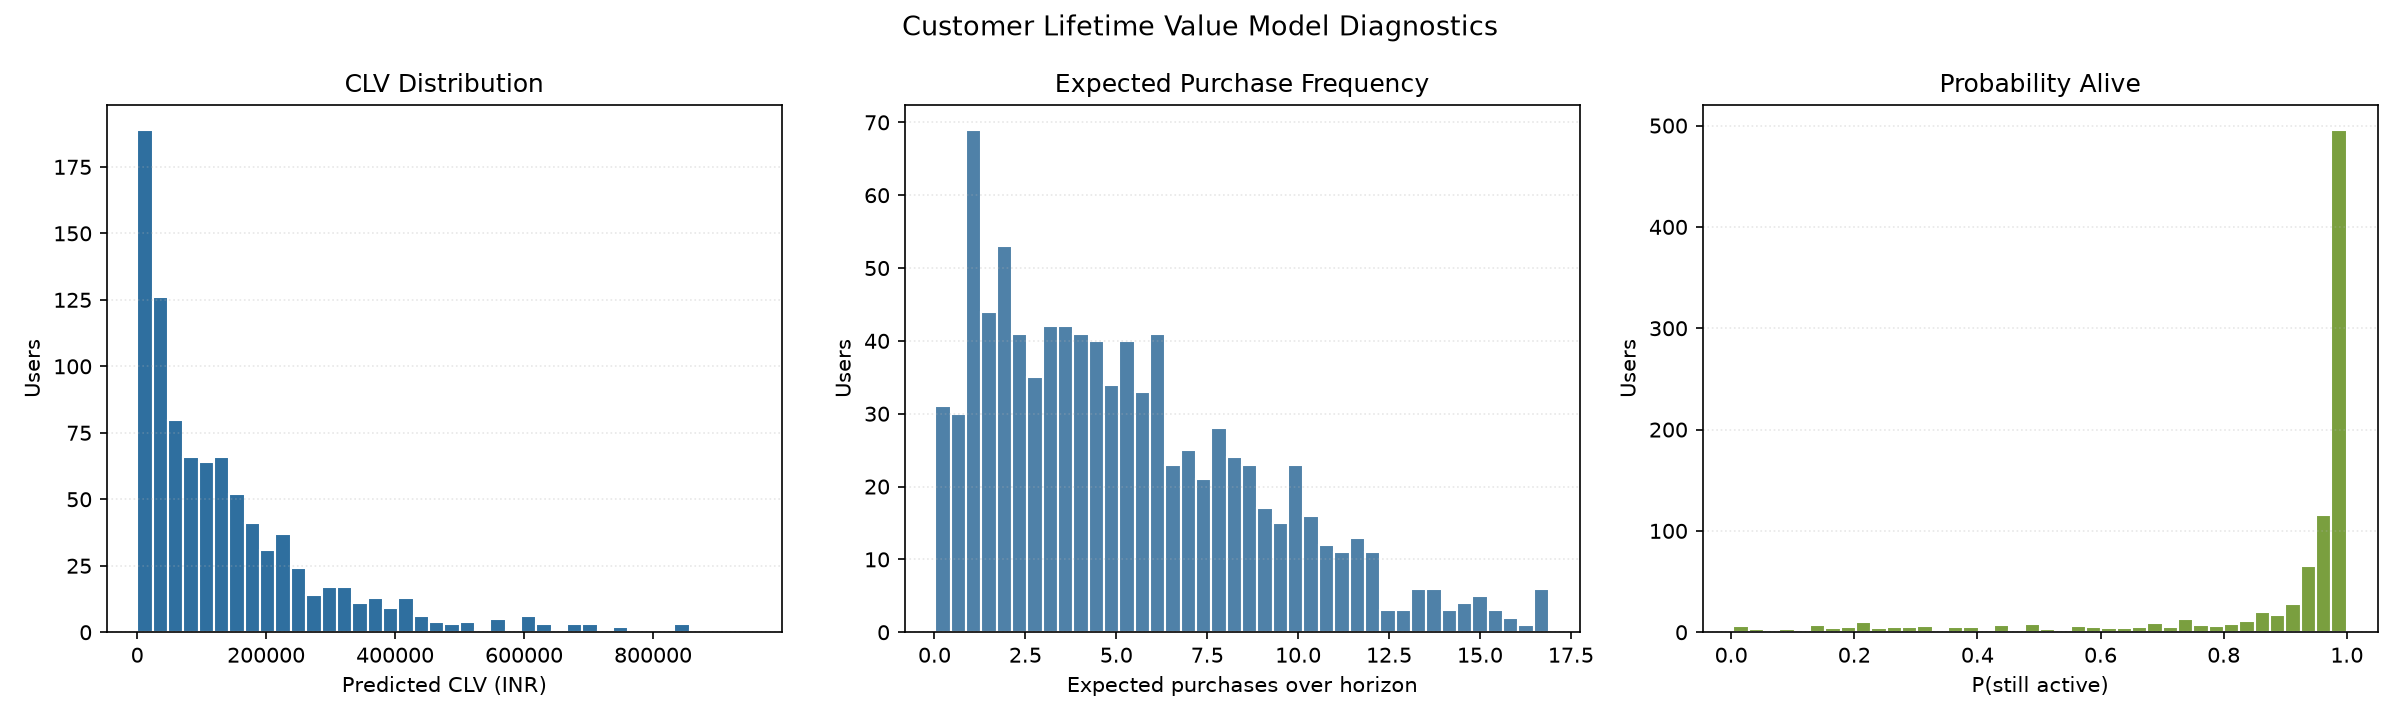

In [18]:
show("clv_distribution.png")

In [19]:
clv_df = pl.read_parquet(USER_CLV_PATH)
cols = ["user_id", "frequency", "predicted_purchases", "predicted_avg_order_value",
        "predicted_clv", "probability_alive", "order_value_estimate_source"]
if "archetype" in clv_df.columns:
    cols.append("archetype")

print("Top 10 users by predicted CLV")
print(clv_df.select(cols).head(10))
print()
print("Bottom 10 users by predicted CLV")
print(clv_df.select(cols).tail(10))

Top 10 users by predicted CLV
shape: (10, 8)
┌───────────┬───────────┬────────────────────┬────────────────────┬───────────────┬───────────────────┬───────────────────┬────────────────┐
│ user_id   ┆ frequency ┆ predicted_purchase ┆ predicted_avg_orde ┆ predicted_clv ┆ probability_alive ┆ order_value_estim ┆ archetype      │
│ ---       ┆ ---       ┆ s                  ┆ r_value            ┆ ---           ┆ ---               ┆ ate_source        ┆ ---            │
│ str       ┆ f64       ┆ ---                ┆ ---                ┆ f64           ┆ f64               ┆ ---               ┆ str            │
│           ┆           ┆ f64                ┆ f64                ┆               ┆                   ┆ str               ┆                │
╞═══════════╪═══════════╪════════════════════╪════════════════════╪═══════════════╪═══════════════════╪═══════════════════╪════════════════╡
│ user_0296 ┆ 14.0      ┆ 8.222287           ┆ 115785.268199      ┆ 952019.697897 ┆ 0.983838          ┆ gamma

In [20]:
if "archetype" in clv_df.columns:
    profile = (clv_df.group_by("archetype")
               .agg([
                   pl.len().alias("users"),
                   pl.col("predicted_clv").mean().round(0).alias("mean_clv"),
                   pl.col("predicted_purchases").mean().round(2).alias("mean_purchases"),
                   pl.col("probability_alive").mean().round(3).alias("mean_p_alive"),
               ])
               .sort("mean_clv", descending=True))
    print(profile)
    print()
    print("The archetype is simulator ground truth and is never a model feature. Predicted CLV")
    print("ordering the archetypes correctly is an independent check that the model recovered")
    print("the latent behavior that generated the data.")

shape: (5, 5)
┌────────────────────┬───────┬──────────┬────────────────┬──────────────┐
│ archetype          ┆ users ┆ mean_clv ┆ mean_purchases ┆ mean_p_alive │
│ ---                ┆ ---   ┆ ---      ┆ ---            ┆ ---          │
│ str                ┆ u32   ┆ f64      ┆ f64            ┆ f64          │
╞════════════════════╪═══════╪══════════╪════════════════╪══════════════╡
│ impulse_buyer      ┆ 187   ┆ 185612.0 ┆ 6.87           ┆ 0.821        │
│ loyalist           ┆ 205   ┆ 178947.0 ┆ 5.78           ┆ 0.911        │
│ comparison_shopper ┆ 194   ┆ 142841.0 ┆ 5.51           ┆ 0.868        │
│ bargain_hunter     ┆ 198   ┆ 126479.0 ┆ 5.08           ┆ 0.899        │
│ window_shopper     ┆ 136   ┆ 50889.0  ┆ 2.23           ┆ 0.888        │
└────────────────────┴───────┴──────────┴────────────────┴──────────────┘

The archetype is simulator ground truth and is never a model feature. Predicted CLV
ordering the archetypes correctly is an independent check that the model recovered
the 

## 5. User Segmentation

KMeans on up to twelve interpretable behavioral features, with the cluster count chosen by
silhouette score rather than assumed. Features that are constant across users are dropped first,
and a segment name is only assigned when the features defining it are populated and the cluster
resembles it closely; otherwise the cluster stays unclassified rather than mislabelled. HDBSCAN runs alongside as a density-based cross-check that can label
users as belonging to no cluster at all.

In [21]:
print(pl.DataFrame(segmentation["k_selection"]))
print()
print(f"Selected k: {segmentation['selected_k']} (highest silhouette)")
print()
km = segmentation["kmeans_quality"]
hdb = segmentation["hdbscan_quality"]
print(f"KMeans : {km['n_clusters']} clusters, silhouette {km['silhouette']:.4f}")
print(f"         sizes {km['cluster_sizes']}")
print(f"HDBSCAN: {hdb['n_clusters']} clusters, silhouette {hdb['silhouette']:.4f}, "
      f"{hdb['n_noise']} noise points ({hdb['noise_fraction']:.1%})")
print()
print("Inertia falls monotonically with k, so it can only ever suggest an elbow. Silhouette and")
print("Davies-Bouldin penalize over-splitting, which is why k is chosen on those instead.")

shape: (4, 5)
┌─────┬─────────────┬────────────┬────────────────┬───────────────────┐
│ k   ┆ inertia     ┆ silhouette ┆ davies_bouldin ┆ calinski_harabasz │
│ --- ┆ ---         ┆ ---        ┆ ---            ┆ ---               │
│ i64 ┆ f64         ┆ f64        ┆ f64            ┆ f64               │
╞═════╪═════════════╪════════════╪════════════════╪═══════════════════╡
│ 3   ┆ 6634.09514  ┆ 0.292169   ┆ 1.278445       ┆ 403.205489        │
│ 4   ┆ 5743.814979 ┆ 0.298834   ┆ 1.192798       ┆ 361.615657        │
│ 5   ┆ 5069.177867 ┆ 0.306564   ┆ 1.21402        ┆ 340.102883        │
│ 6   ┆ 4561.826092 ┆ 0.269638   ┆ 1.16637        ┆ 324.148475        │
└─────┴─────────────┴────────────┴────────────────┴───────────────────┘

Selected k: 5 (highest silhouette)

KMeans : 5 clusters, silhouette 0.3066
         sizes {'0': 76, '1': 319, '2': 455, '3': 98, '4': 52}
HDBSCAN: 2 clusters, silhouette 0.4833, 145 noise points (14.5%)

Inertia falls monotonically with k, so it can only ever sugge

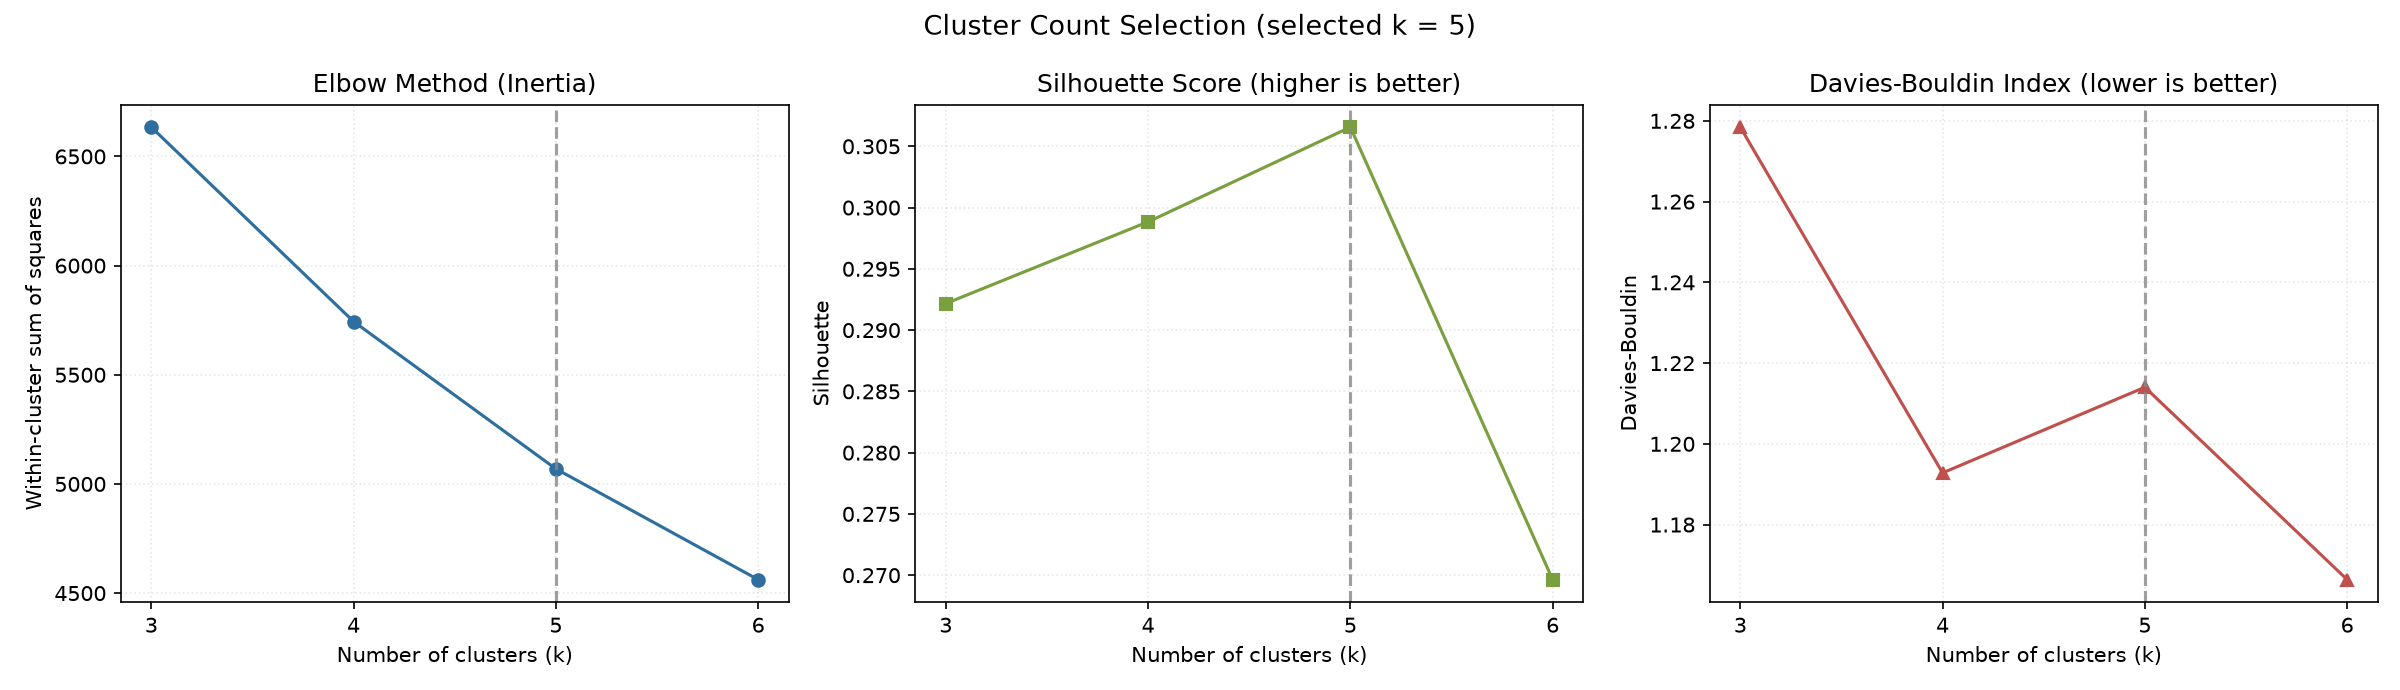

In [22]:
show("segmentation_elbow_silhouette.png")

In [23]:
for seg in segmentation["segments"]:
    print(f"  Cluster {seg['cluster']} \"{seg['name']}\" -- {seg['description']}")

print()
profile_cols = ["cluster", "users", "total_events_30d", "total_purchases_30d",
                "total_spend_30d", "app_entropy", "cross_app_comparison_count",
                "avg_discount_pct_on_purchases"]
prof = pl.DataFrame(segmentation["cluster_profile"]).select(
    [c for c in profile_cols if c in segmentation["cluster_profile"][0]]
)
print(prof)

  Cluster 0 "Bargain Hunters" -- 76 users with high pct purchases with discount, high avg discount pct on purchases, low view to cart ratio
  Cluster 1 "Single-App Regulars" -- 319 users with high dominant app share, low app entropy, low cross app comparison count
  Cluster 2 "Comparison Shoppers" -- 455 users with high cross app comparison count, low dominant app share, high app entropy
  Cluster 3 "Window Shoppers" -- 98 users with low avg order value, low total spend 30d, high days since last purchase
  Cluster 4 "Occasional Buyers" -- 52 users with low total events 30d, low total spend 30d, high days since last purchase

shape: (5, 8)
┌─────────┬───────┬──────────────────┬─────────────────────┬─────────────────┬─────────────┬───────────────────────┬───────────────────────┐
│ cluster ┆ users ┆ total_events_30d ┆ total_purchases_30d ┆ total_spend_30d ┆ app_entropy ┆ cross_app_comparison_ ┆ avg_discount_pct_on_p │
│ ---     ┆ ---   ┆ ---              ┆ ---                 ┆ ---       

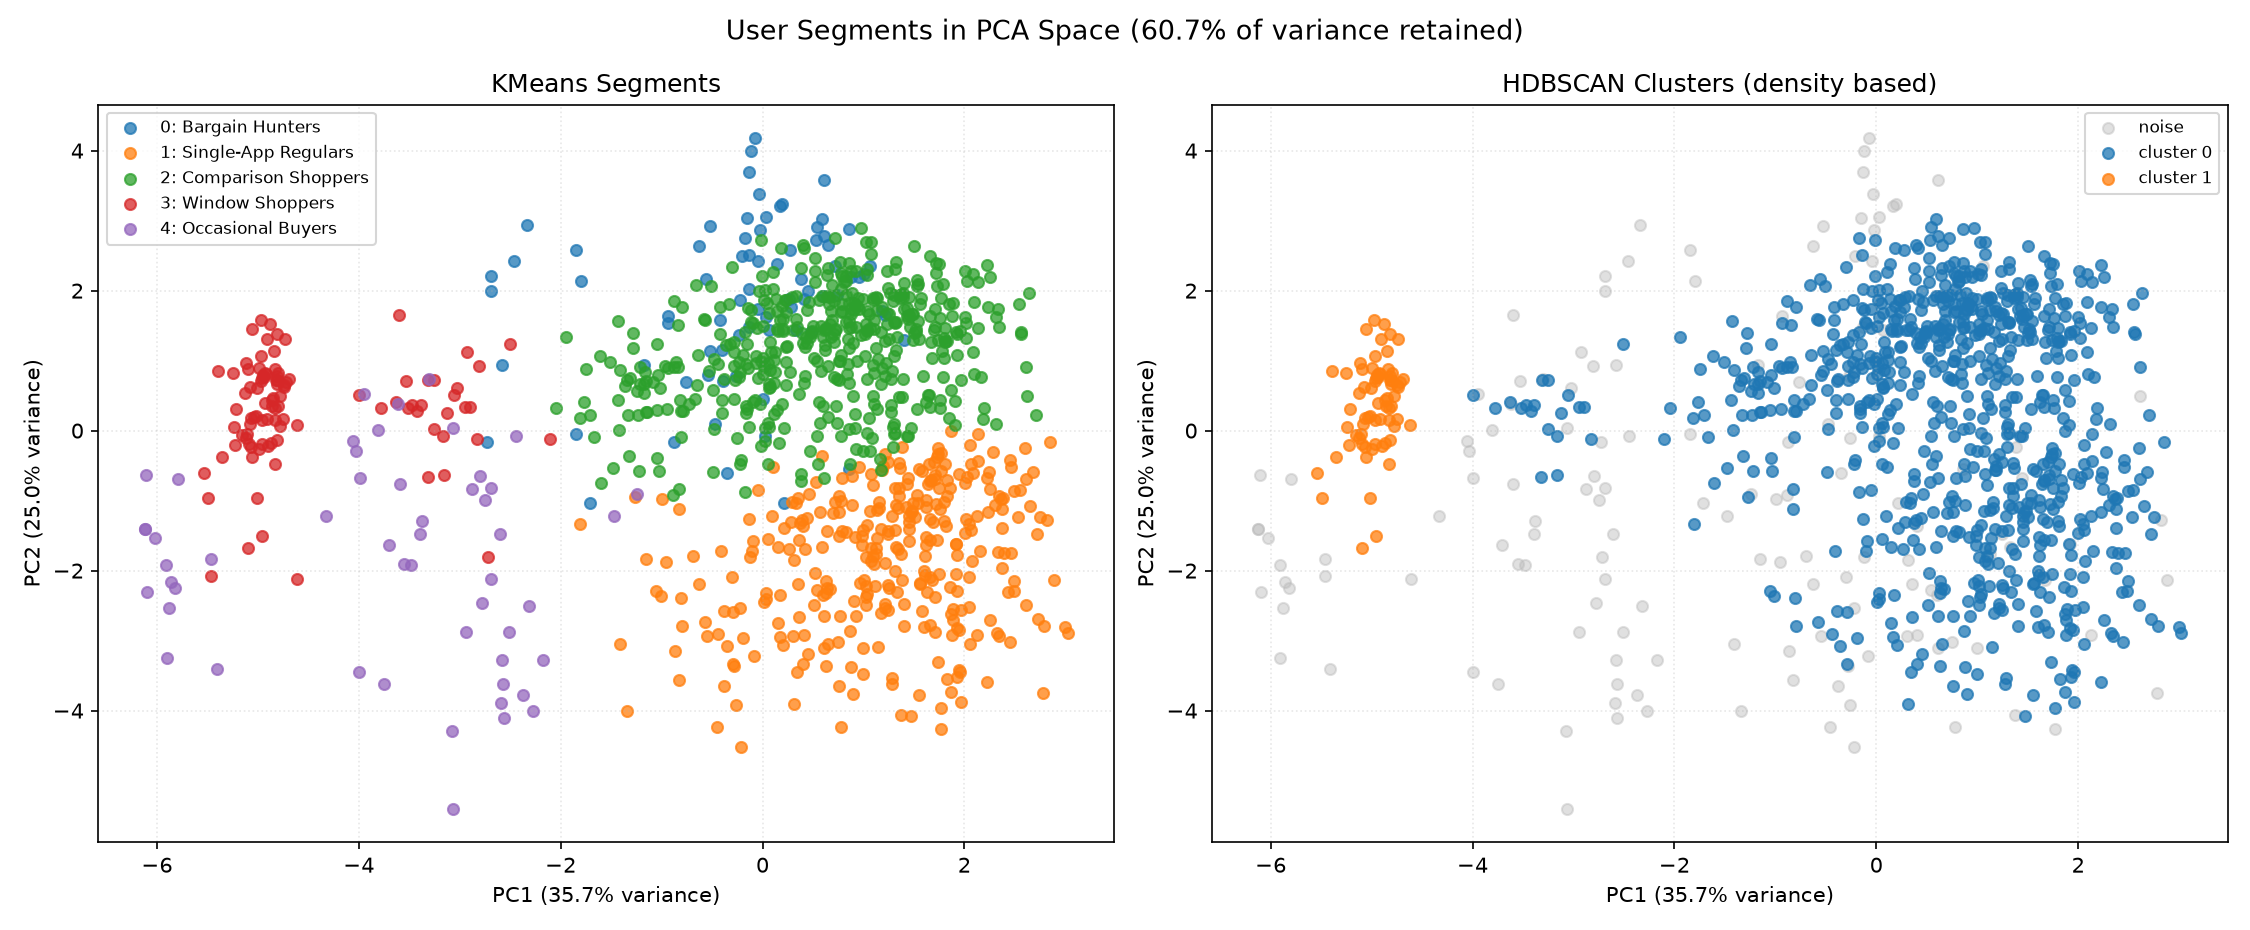

The two plotted components retain 60.7% of the
variance, so visually overlapping points may still be well separated in the full
twelve-dimensional space the clustering actually used.


In [24]:
show("segmentation_pca_scatter.png")

print(f"The two plotted components retain {segmentation['pca_explained_variance']:.1%} of the")
print("variance, so visually overlapping points may still be well separated in the full")
print("twelve-dimensional space the clustering actually used.")

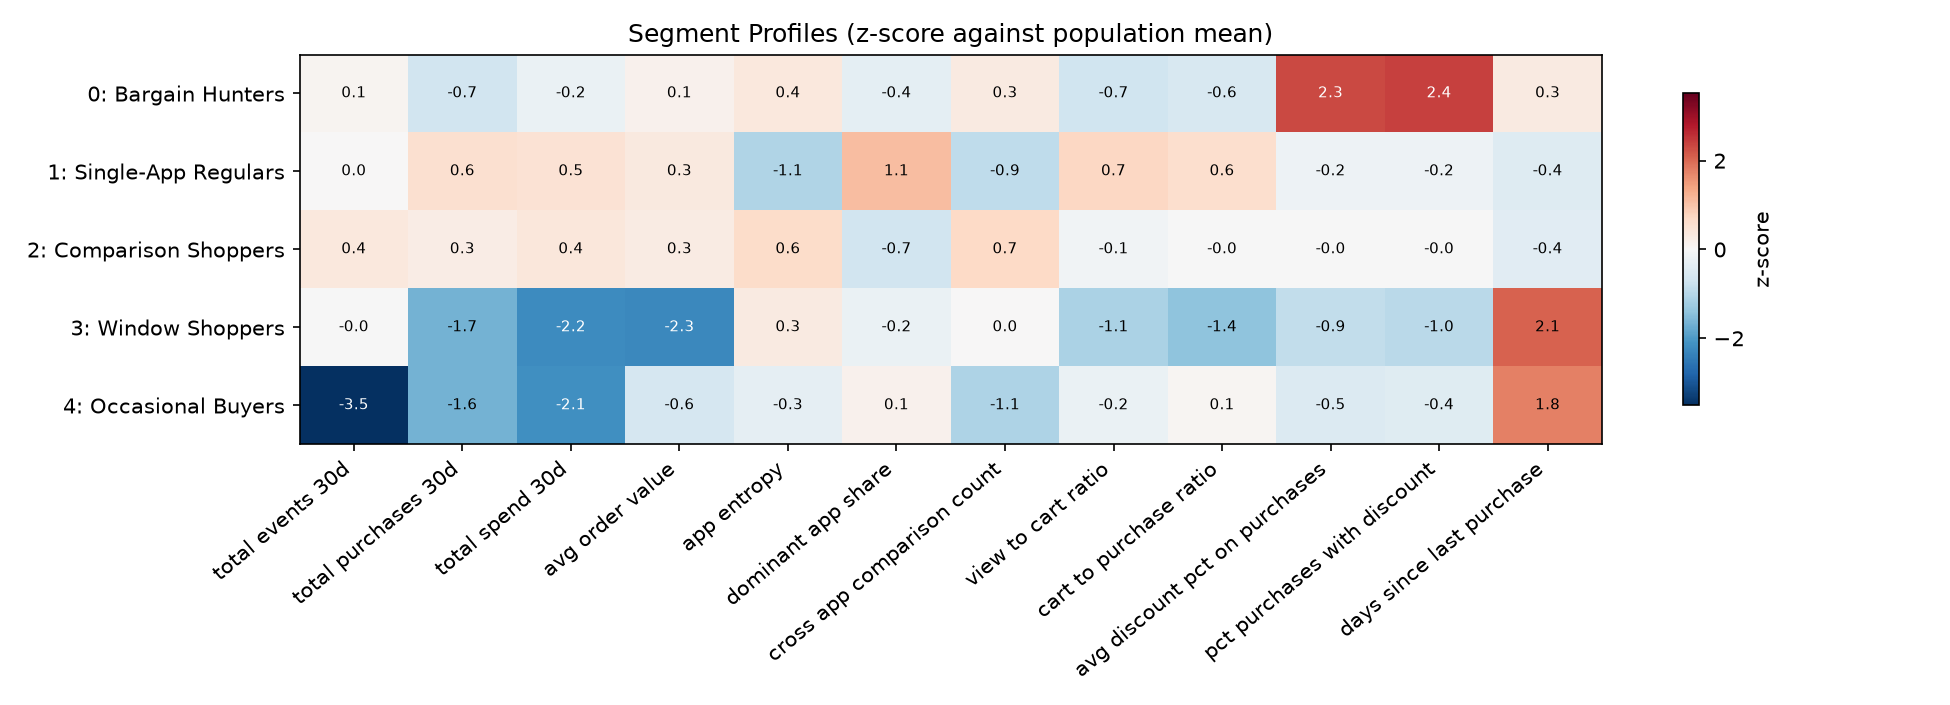

In [25]:
show("segmentation_cluster_profiles.png")

## 6. Business Recommendations

Three actions follow from the results above. Each names the evidence it rests on.

### Recommendation 1: suppress the bottom propensity deciles from paid retention campaigns

The two lowest-scored deciles contain no purchasers at all in the test window, against a
population purchase rate near 40 percent. Dropping the bottom 20 percent of the scored
population from a paid campaign removes a fifth of contact cost while giving up effectively
none of the conversions. Because the model is already calibrated, the cutoff can be set on a
predicted-probability threshold tied to campaign margin rather than on an arbitrary decile.

### Recommendation 2: defend the Comparison Shopper and Bargain Hunter segments with price guarantees, not discounts

SHAP attribution puts cart activity, the view-to-cart ratio, at the top of the drivers of
buying on a non-dominant app, and the Comparison Shoppers segment combines the highest mean
discount with by far the most cross-app comparisons. These users are shopping the same item
across apps and buying wherever it is cheapest, so a blanket discount subsidizes purchases that
would often have happened anyway. A price-match guarantee surfaced at the comparison moment
targets the actual decision point instead.

### Recommendation 3: treat VIP Loyalists as a retention problem, and size the effort by CLV, not by spend

The VIP Loyalist segment is small but concentrated: it carries by far the highest purchase
frequency, spend, and predicted CLV of any segment. Rank retention spend by predicted CLV
rather than trailing spend, since CLV already folds in the probability that a customer is still
active. The CLV model's P(alive) term is the operational signal here, as it separates a
genuinely dormant high spender from a merely quiet one.

### What this cannot tell you

The targets are 7-day forward windows over a 30-day simulated history, so nothing here speaks
to seasonality, to long-run retention, or to how these users respond to an *intervention*.
Every result above is observational: it describes what users did, not what they would have done
had they been treated differently. Acting on any of these recommendations warrants a holdout
test to measure the causal effect.

In [26]:
print("Model artifact inventory")
print()
for path in sorted(ARTIFACTS_DIR.iterdir()):
    if path.name == ".gitkeep":
        continue
    print(f"  {path.name:<48} {path.stat().st_size / 1024:>8.1f} KB")

Model artifact inventory

  clv_bgnbd.joblib                                     31.7 KB
  clv_distribution.png                                 85.9 KB
  clv_gammagamma.joblib                                22.4 KB
  clv_summary.json                                      8.7 KB
  propensity_calibration_curve.png                    133.8 KB
  propensity_cumulative_gains.png                     104.8 KB
  propensity_evaluation_summary.json                    4.2 KB
  propensity_feature_importance.png                    93.4 KB
  propensity_lgbm.joblib                              111.7 KB
  propensity_lgbm_calibrated.joblib                    84.6 KB
  propensity_lift_chart.png                            66.1 KB
  propensity_metrics.json                               2.6 KB
  propensity_roc_pr_curves.png                        132.3 KB
  segmentation_cluster_profiles.png                   141.3 KB
  segmentation_elbow_silhouette.png                   145.4 KB
  segmentation_kmeans.joblib 